In [6]:
import pandas as pd

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print("train:", train.shape, "| test:", test.shape)
print("only in train:", [c for c in train.columns if c not in test.columns])
print("only in test :", [c for c in test.columns if c not in train.columns])
print(list(train.columns))
train.head()

train: (32940, 22) | test: (8236, 20)
only in train: ['duration', 'y']
only in test : []
['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


In [ ]:
# stage 1: data overview
import sys
import numpy as np
import sklearn
from sklearn.feature_selection import mutual_info_classif

print(sys.version.split()[0], np.__version__, pd.__version__, sklearn.__version__)

SEED = 2305         
ID_COL = "id"
TARGET = "y" 

train[TARGET] = (train[TARGET] == "yes").astype(int)

y = train[TARGET]
print(y.value_counts())
print(y.value_counts(normalize=True).round(4))
print("accuracy of 'always the majority class':", round(y.value_counts(normalize=True).max(), 4))

features = [c for c in test.columns if c != ID_COL]         
overview = pd.DataFrame({
    "dtype": train[features].dtypes.astype(str),
    "n_unique": train[features].nunique(),
    "n_nan": train[features].isna().sum(),
})
display(overview)

WORDS = {"unknown", "?", "na", "n/a", "none", "null", "nan", "", "-"}


def scan_special_values(df, cols, min_share=0.01):
    rows = []
    for c in cols:
        s = df[c]
        if not pd.api.types.is_numeric_dtype(s):
            low = s.astype(str).str.strip().str.lower()
            for w in WORDS & set(low.unique()):
                rows.append((c, repr(w), int((low == w).sum())))
        else:
            for v in (s.min(), s.max(), 0, -1):
                k = int((s == v).sum())
                if k / len(s) >= min_share:
                    rows.append((c, v, k))
    out = pd.DataFrame(rows, columns=["column", "suspicious value", "count"]).drop_duplicates()
    out["share"] = (out["count"] / len(df)).round(4)
    return out.sort_values("count", ascending=False)


display(scan_special_values(train, features))

print("id strictly increasing in train:", train[ID_COL].is_monotonic_increasing,
      "| train ids", train[ID_COL].min(), "-", train[ID_COL].max(),
      "| test ids", test[ID_COL].min(), "-", test[ID_COL].max())
chunks = np.array_split(train[TARGET].to_numpy(), 10)
print("target rate by tenth of the file:", [round(float(c.mean()), 3) for c in chunks])


X = train[features].copy()
is_cat = pd.Series({c: not pd.api.types.is_numeric_dtype(X[c]) for c in X.columns})
for c in X.columns[is_cat.to_numpy()]:
    X[c] = pd.factorize(X[c])[0]
X = X.fillna(X.median(numeric_only=True))
mi = mutual_info_classif(X, y, discrete_features=is_cat.to_numpy(), random_state=SEED)
relation = pd.Series(mi, index=features, name="mutual information").sort_values(ascending=False).round(4)
display(relation.to_frame())


def rate_by_group(col, q=5):
    s = train[col]
    if not pd.api.types.is_numeric_dtype(s) or s.nunique() <= 10:
        groups = s
    else:
        groups = pd.qcut(s, q, duplicates="drop")
        if groups.nunique() < 2:                      
            groups = pd.cut(s, q)
    return train.groupby(groups, observed=True)[TARGET].agg(["mean", "size"]).round(3)


display(rate_by_group(relation.index[0]))    

3.13.0 2.5.3 3.0.5 1.9.1
train: (32940, 22) | test: (8236, 20)
only in train: ['duration', 'y']
only in test : []
y
0    29229
1     3711
Name: count, dtype: int64
y
0    0.8873
1    0.1127
Name: proportion, dtype: float64
accuracy of 'always the majority class': 0.8873


,dtype,n_unique,n_nan
age,int64,76,0
job,str,12,0
marital,str,4,0
education,str,8,0
default,str,3,0
housing,str,3,0
loan,str,3,0
contact,str,2,0
month,str,10,0
day_of_week,str,5,0


,column,suspicious value,count,share
7,pdays,999,31694,0.9622
8,previous,0,28446,0.8636
6,campaign,1,14108,0.4283
15,nr.employed,5228.1,13038,0.3958
11,emp.var.rate,1.4,13038,0.3958
3,default,'unknown',6871,0.2086
2,education,'unknown',1401,0.0425
10,emp.var.rate,-3.4,862,0.0262
4,housing,'unknown',794,0.0241
5,loan,'unknown',794,0.0241


id strictly increasing in train: True | train ids 0 - 32939 | test ids 32940 - 41175
target rate by tenth of the file: [0.108, 0.118, 0.111, 0.113, 0.105, 0.115, 0.109, 0.116, 0.114, 0.117]


,mutual information
euribor3m,0.0767
cons.conf.idx,0.0718
cons.price.idx,0.0692
nr.employed,0.0677
emp.var.rate,0.0555
pdays,0.0381
poutcome,0.0309
month,0.0262
previous,0.0171
age,0.0148


,mean,size
euribor3m,,
"(0.633, 1.299]",0.299,6924
"(1.299, 4.191]",0.106,6713
"(4.191, 4.864]",0.035,6720
"(4.864, 4.962]",0.057,6819
"(4.962, 5.045]",0.054,5764


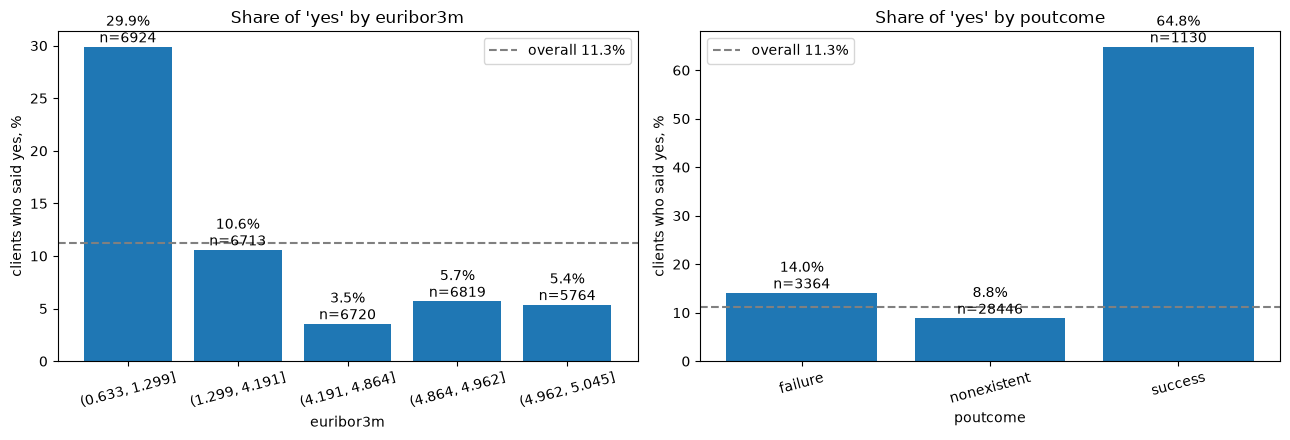

dev: (26352, 19) 0.1127 | hold-out: (6588, 19) 0.1126
categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
numeric: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pdays']
mean of euribor3m on the whole dev part: 3.620696
fold 0: scaler learned 3.627892 | mean of this fold's training rows 3.627892
fold 1: scaler learned 3.616982 | mean of this fold's training rows 3.616982
fold 2: scaler learned 3.622016 | mean of this fold's training rows 3.622016
fold 3: scaler learned 3.620092 | mean of this fold's training rows 3.620092
fold 4: scaler learned 3.616500 | mean of this fold's training rows 3.616500
roc_auc        B minus A: mean -0.0000, std 0.0001, per fold [-0.     -0.0001 -0.0001 -0.      0.0001]
avg_precision  B minus A: mean -0.0007, std 0.0007, per fold [-0.0004  0.0001 -0.002  -0.0003 -0.0008]
roc_auc        B minus C: mean -0.0001, std 0.0006, pe

,accuracy,roc_auc,avg_precision,precision@10%,lift@10%
model,,,,,
majority class,0.8873 ± 0.0001,0.5000 ± 0.0000,0.1127 ± 0.0001,0.1116 ± 0.0139,0.99
logistic regression,0.9007 ± 0.0030,0.7880 ± 0.0133,0.4512 ± 0.0243,0.5006 ± 0.0236,4.44


In [ ]:
# stage 2: plots, stage 3: validation, stage 4: preprocessing, stage 5: baselines
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# stage 2
base_rate = train[TARGET].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (col, groups) in zip(axes, [
    ("euribor3m", pd.qcut(train["euribor3m"], 5, duplicates="drop")),
    ("poutcome", train["poutcome"]),
]):
    r = train.groupby(groups, observed=True)[TARGET].agg(["mean", "size"])
    bars = ax.bar(range(len(r)), r["mean"] * 100)
    ax.bar_label(bars, labels=[f"{m:.1%}\nn={n}" for m, n in zip(r["mean"], r["size"])])
    ax.set_xticks(range(len(r)), [str(i) for i in r.index], rotation=15)
    ax.axhline(base_rate * 100, ls="--", color="gray", label=f"overall {base_rate:.1%}")
    ax.set_xlabel(col)
    ax.set_ylabel("clients who said yes, %")
    ax.set_title(f"Share of 'yes' by {col}")
    ax.legend()
plt.tight_layout()
plt.show()

# stage 3
features = [c for c in test.columns if c != ID_COL]                       
cat_cols = [c for c in features if not pd.api.types.is_numeric_dtype(train[c])]
num_cols = [c for c in features if c not in cat_cols and c != "pdays"]    

dev, hold = train_test_split(train, test_size=0.2, stratify=train[TARGET], random_state=SEED)
X_dev, y_dev = dev[features], dev[TARGET].to_numpy()
X_hold, y_hold = hold[features], hold[TARGET].to_numpy()                 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("dev:", X_dev.shape, round(y_dev.mean(), 4), "| hold-out:", X_hold.shape, round(y_hold.mean(), 4))
print("categorical:", cat_cols)
print("numeric:", num_cols + ["pdays"])


def precision_at_10pct(y_true, y_score):
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    k = int(round(0.10 * len(y_true)))
    top = np.argsort(-y_score, kind="stable")[:k]
    return y_true[top].mean()


RANKING = {
    "roc_auc": "roc_auc",
    "avg_precision": "average_precision",
    "precision@10%": make_scorer(precision_at_10pct, response_method=("decision_function", "predict_proba")),
}


def evaluate(name, model, scoring=RANKING):
    s = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring)
    fold_scores[name] = {k: s[f"test_{k}"] for k in scoring}
    row = {"model": name}
    for k in scoring:
        row[k] = f"{s[f'test_{k}'].mean():.4f} ± {s[f'test_{k}'].std():.4f}"
    row["lift@10%"] = round(s["test_precision@10%"].mean() / y_dev.mean(), 2) if "precision@10%" in scoring else None
    return row


fold_scores = {}


# stage 4: preprocessing inside the pipeline
def make_preprocessor(pdays_mode="flag", unknown_mode="category"):
    numeric = Pipeline([("scale", StandardScaler())])
    if pdays_mode == "flag":
        pdays = Pipeline([
            ("fill", SimpleImputer(missing_values=999, strategy="constant", fill_value=0, add_indicator=True)),
            ("scale", StandardScaler()),
        ])
    else:
        pdays = Pipeline([("scale", StandardScaler())])
    cat_steps = []
    if unknown_mode == "impute":
        cat_steps.append(("fill", SimpleImputer(missing_values="unknown", strategy="most_frequent")))
    cat_steps.append(("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)))
    return ColumnTransformer([
        ("num", numeric, num_cols),
        ("pdays", pdays, ["pdays"]),
        ("cat", Pipeline(cat_steps), cat_cols),
    ])


def make_model(clf, **prep_kwargs):
    return Pipeline([("prep", make_preprocessor(**prep_kwargs)), ("clf", clf)])


logreg = lambda: LogisticRegression(max_iter=2000)

# stage 4: evidence that nothing leaks
s = cross_validate(make_model(logreg()), X_dev, y_dev, cv=cv, scoring="roc_auc", return_estimator=True)
j = num_cols.index("euribor3m")
print(f"mean of euribor3m on the whole dev part: {X_dev['euribor3m'].mean():.6f}")
for i, ((tr_idx, _), est) in enumerate(zip(cv.split(X_dev, y_dev), s["estimator"])):
    fitted = est.named_steps["prep"].named_transformers_["num"]["scale"].mean_[j]
    train_fold_mean = X_dev["euribor3m"].iloc[tr_idx].mean()
    print(f"fold {i}: scaler learned {fitted:.6f} | mean of this fold's training rows {train_fold_mean:.6f}")
    assert np.isclose(fitted, train_fold_mean)       

# stage 4: compare preprocessing choices with CV numbers (logistic regression)
rows = [
    evaluate("A: pdays raw, unknown = category", make_model(logreg(), pdays_mode="raw", unknown_mode="category")),
    evaluate("B: pdays flag, unknown = category", make_model(logreg(), pdays_mode="flag", unknown_mode="category")),
    evaluate("C: pdays flag, unknown imputed", make_model(logreg(), pdays_mode="flag", unknown_mode="impute")),
]
pd.DataFrame(rows).set_index("model")


for a, b in [("B: pdays flag, unknown = category", "A: pdays raw, unknown = category"),
             ("B: pdays flag, unknown = category", "C: pdays flag, unknown imputed")]:
    for metric in ("roc_auc", "avg_precision"):
        d = fold_scores[a][metric] - fold_scores[b][metric]
        print(f"{metric:14s} {a[0]} minus {b[0]}: mean {d.mean():+.4f}, std {d.std():.4f}, per fold {np.round(d, 4)}")

# stage 5: baselines on the same folds
PREP = dict(pdays_mode="flag", unknown_mode="category")     
WITH_ACCURACY = {"accuracy": "accuracy", **RANKING}
baselines = [
    evaluate("majority class", DummyClassifier(strategy="most_frequent"), scoring=WITH_ACCURACY),
    evaluate("logistic regression", make_model(logreg(), **PREP), scoring=WITH_ACCURACY),
]
pd.DataFrame(baselines).set_index("model")

In [ ]:
# stage 6: compare model families, tune by CV, imbalance handling
import time

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier


SEARCH = {
    "logistic regression (tuned)": (LogisticRegression(max_iter=2000), {"C": [0.01, 0.1, 1, 10]}),
    "decision tree": (DecisionTreeClassifier(random_state=SEED),
                      {"max_depth": [3, 5, 8], "min_samples_leaf": [20, 50, 100]}),
    "random forest": (RandomForestClassifier(n_estimators=300, random_state=SEED),
                      {"max_depth": [6, 10, None], "min_samples_leaf": [5, 20, 50]}),
    "hist gradient boosting": (HistGradientBoostingClassifier(max_iter=300, early_stopping=True, random_state=SEED),
                               {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [8, 15, 31], "min_samples_leaf": [20, 50]}),
}
TUNE_ON = "avg_precision"      
tuned = {}


def tune(name, clf, grid):
    pipe = make_model(clf, **PREP)
    gs = GridSearchCV(pipe, {f"clf__{k}": v for k, v in grid.items()}, scoring=RANKING,
                      refit=TUNE_ON, cv=cv, n_jobs=-1)
    gs.fit(X_dev, y_dev)
    i = gs.best_index_
    fold_scores[name] = {m: np.array([gs.cv_results_[f"split{k}_test_{m}"][i] for k in range(cv.get_n_splits())])
                         for m in RANKING}
    tuned[name] = gs
    return gs


def summarise(names):
    rows = []
    for n in names:
        row = {"model": n}
        for m in RANKING:
            row[m] = f"{fold_scores[n][m].mean():.4f} ± {fold_scores[n][m].std():.4f}"
        row["lift@10%"] = round(fold_scores[n]["precision@10%"].mean() / y_dev.mean(), 2)
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")



for name, (clf, grid) in SEARCH.items():
    t0 = time.time()
    gs = tune(name, clf, grid)
    print(f"{name}: best params {gs.best_params_} | {time.time() - t0:.0f} s")

summarise(["majority class", "logistic regression"] + list(SEARCH))



def compare(a, b, metric="avg_precision"):
    d = fold_scores[a][metric] - fold_scores[b][metric]
    verdict = "consistent" if ((d > 0).all() or (d < 0).all()) and abs(d.mean()) > d.std() else "inside the noise"
    print(f"{metric:14s} {a}  minus  {b}: mean {d.mean():+.4f}, std {d.std():.4f}, "
          f"folds >0: {(d > 0).sum()}/{len(d)}  ->  {verdict}")


ranking = sorted(SEARCH, key=lambda n: fold_scores[n][TUNE_ON].mean(), reverse=True)
print("order by mean", TUNE_ON, ":", ranking)
for metric in ("avg_precision", "roc_auc", "precision@10%"):
    compare(ranking[0], "logistic regression", metric)    
    compare(ranking[0], ranking[1], metric)               
    print()


for name in SEARCH:
    balanced = clone(tuned[name].best_estimator_).set_params(clf__class_weight="balanced")
    evaluate(f"{name} + balanced", balanced)
summarise([x for n in SEARCH for x in (n, f"{n} + balanced")])


for name in SEARCH:
    for metric in ("avg_precision", "roc_auc", "precision@10%"):
        compare(f"{name} + balanced", name, metric)

logistic regression (tuned): best params {'clf__C': 1} | 13 s
decision tree: best params {'clf__max_depth': 8, 'clf__min_samples_leaf': 100} | 5 s
random forest: best params {'clf__max_depth': None, 'clf__min_samples_leaf': 20} | 81 s
hist gradient boosting: best params {'clf__learning_rate': 0.03, 'clf__max_leaf_nodes': 15, 'clf__min_samples_leaf': 20} | 23 s
order by mean avg_precision : ['hist gradient boosting', 'random forest', 'logistic regression (tuned)', 'decision tree']
avg_precision  hist gradient boosting  minus  logistic regression: mean +0.0156, std 0.0060, folds >0: 5/5  ->  consistent
avg_precision  hist gradient boosting  minus  random forest: mean +0.0041, std 0.0026, folds >0: 4/5  ->  inside the noise

roc_auc        hist gradient boosting  minus  logistic regression: mean +0.0114, std 0.0037, folds >0: 5/5  ->  consistent
roc_auc        hist gradient boosting  minus  random forest: mean +0.0063, std 0.0034, folds >0: 5/5  ->  consistent

precision@10%  hist gradien

hold-out ROC-AUC = 0.8173 | average precision = 0.4953


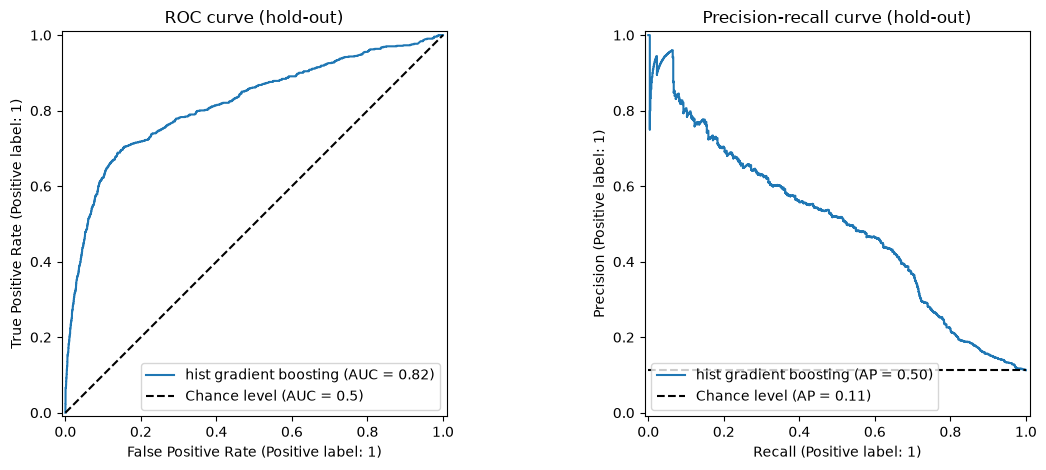

clients in hold-out: 6588, of them real 'yes': 742 (11.26%)
cutoff (score of the last called client): 0.3270
called: 659 | said yes: 354 -> precision = 0.5372 ± 0.0194 (standard error)
recall = 354/742 = 0.4771
lift over calling at random = 0.5372 / 0.1126 = 4.77
model.joblib size, MB: 0.27 (limit 50)
(8236, 3) | called: 824 (10.00%)


CompletedProcess(args=['c:\\Users\\77772\\Desktop\\Machine_learning\\Merkulova_ML_lab_3\\.Merkulova_ML_lab_3\\Scripts\\python.exe', '-c', '\nimport joblib, numpy as np, pandas as pd\nmodel = joblib.load("model.joblib")\nrows = pd.read_csv("data/test.csv").drop(columns=["id"]).head(200)\nsaved = pd.read_csv("predictions.csv").head(200)\nscores = model.predict_proba(rows)[:, 1]\nprint("loaded OK; max |score - predictions.csv| =", float(np.abs(scores - saved["y_score"]).max()))\n'], returncode=0)

In [ ]:
# stage 7: final evaluation (once) and Stage 8: save the model and the predictions
import os
import subprocess
import sys

import joblib
from sklearn.metrics import (PrecisionRecallDisplay, RocCurveDisplay, average_precision_score,
                             confusion_matrix, roc_auc_score)

FINAL = "hist gradient boosting"    


final = clone(tuned[FINAL].best_estimator_).fit(X_dev, y_dev)
hold_scores = final.predict_proba(X_hold)[:, 1]
print(f"hold-out ROC-AUC = {roc_auc_score(y_hold, hold_scores):.4f} | "
      f"average precision = {average_precision_score(y_hold, hold_scores):.4f}")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
RocCurveDisplay.from_predictions(y_hold, hold_scores, ax=axes[0], name=FINAL, plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_hold, hold_scores, ax=axes[1], name=FINAL, plot_chance_level=True)
axes[0].set_title("ROC curve (hold-out)")
axes[1].set_title("Precision-recall curve (hold-out)")
plt.tight_layout()
plt.show()



def top_share_mask(scores, share=0.10):
    k = int(round(share * len(scores)))
    mask = np.zeros(len(scores), dtype=bool)
    mask[np.argsort(-scores, kind="stable")[:k]] = True
    return mask


called = top_share_mask(hold_scores)
tn, fp, fn, tp = confusion_matrix(y_hold, called.astype(int)).ravel()
n_called = int(called.sum())
precision, recall = tp / n_called, tp / y_hold.sum()
lift = precision / y_hold.mean()
se = np.sqrt(precision * (1 - precision) / n_called)

print(f"clients in hold-out: {len(y_hold)}, of them real 'yes': {int(y_hold.sum())} ({y_hold.mean():.2%})")
print(f"cutoff (score of the last called client): {hold_scores[called].min():.4f}")
print(f"called: {n_called} | said yes: {tp} -> precision = {precision:.4f} ± {se:.4f} (standard error)")
print(f"recall = {tp}/{int(y_hold.sum())} = {recall:.4f}")
print(f"lift over calling at random = {precision:.4f} / {y_hold.mean():.4f} = {lift:.2f}")
pd.DataFrame([[tn, fp], [fn, tp]], index=["actually no", "actually yes"], columns=["not called", "called"])

# stage 8: refit on ALL of train.csv, save the model and the predictions
final_full = clone(tuned[FINAL].best_estimator_).fit(train[features], train[TARGET].to_numpy())
joblib.dump(final_full, "model.joblib")
print("model.joblib size, MB:", round(os.path.getsize("model.joblib") / 1e6, 2), "(limit 50)")


test_scores = final_full.predict_proba(test[features])[:, 1]
pred = pd.DataFrame({
    "id": test[ID_COL],
    "y_pred": top_share_mask(test_scores).astype(int),      
    "y_score": test_scores,
})
pred.to_csv("predictions.csv", index=False)
assert pred["id"].is_unique and len(pred) == len(test)
print(pred.shape, "| called:", int(pred["y_pred"].sum()), f"({pred['y_pred'].mean():.2%})")
pred.head()


check = """
import joblib, numpy as np, pandas as pd
model = joblib.load("model.joblib")
rows = pd.read_csv("data/test.csv").drop(columns=["id"]).head(200)
saved = pd.read_csv("predictions.csv").head(200)
scores = model.predict_proba(rows)[:, 1]
print("loaded OK; max |score - predictions.csv| =", float(np.abs(scores - saved["y_score"]).max()))
"""
subprocess.run([sys.executable, "-c", check], check=True)